In [1]:
import pandas as pd
import src.utils.preprocess as preproc
import matplotlib.pyplot as plt

from src.utils import preprocess

In [2]:
data = preproc.load_data_set("https://simplonline-v3-prod.s3.eu-west-3.amazonaws.com/media/file/csv/dataset-electric-6b0361bc9dd9f506891054.csv")
data.columns

Index(['Datetime', 'Consumption'], dtype='str')

In [3]:
data = preproc.convert_to_date_time(data,"Datetime")

In [4]:
preproc.is_ordered(data,"Datetime")

False

In [5]:
data = preproc.fix_chrono_order(data,"Datetime")

In [6]:
preproc.is_ordered(data,"Datetime")

True

In [7]:
data = preproc.set_index(data,"Datetime")

In [8]:
print(data.index.dtype)

datetime64[us]


In [9]:
data = preproc.flag_anomalies(data,"Consumption")

In [10]:
anoo = preproc.flag_anomalies(data,"Consumption")
anoo["is_anomaly"].sum()

np.int64(818)

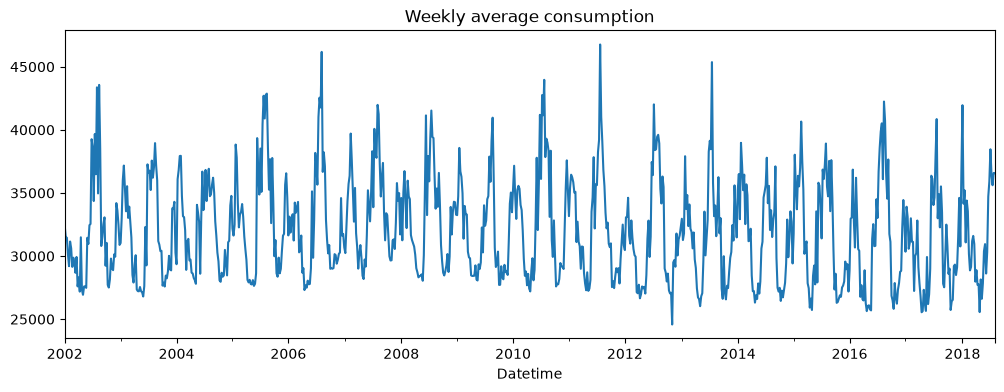

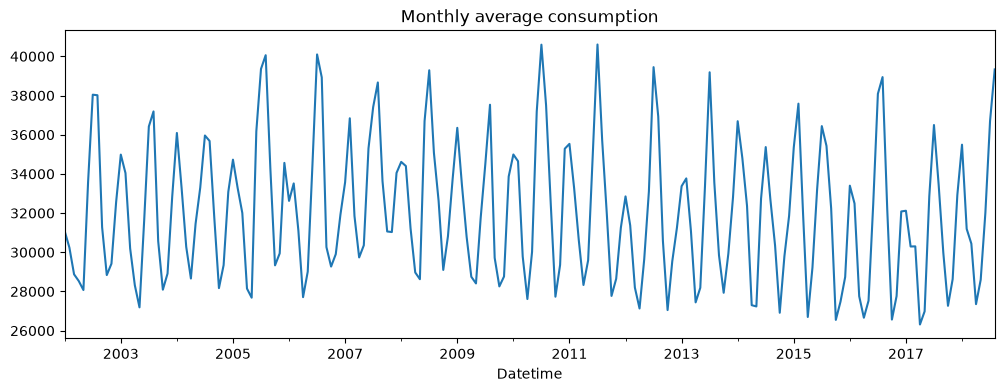

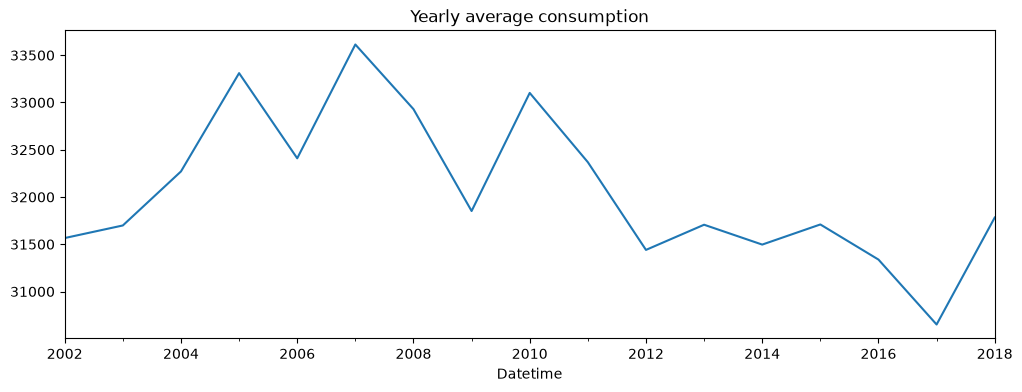

In [11]:
# weekly
data["Consumption"].resample("W").mean().plot(figsize=(12, 4), title="Weekly average consumption")
plt.show()

# Monthly
data["Consumption"].resample("MS").mean().plot(figsize=(12, 4), title="Monthly average consumption")
plt.show()

# Yearly average
data["Consumption"].resample("YS").mean().plot(figsize=(12, 4), title="Yearly average consumption")
plt.show()



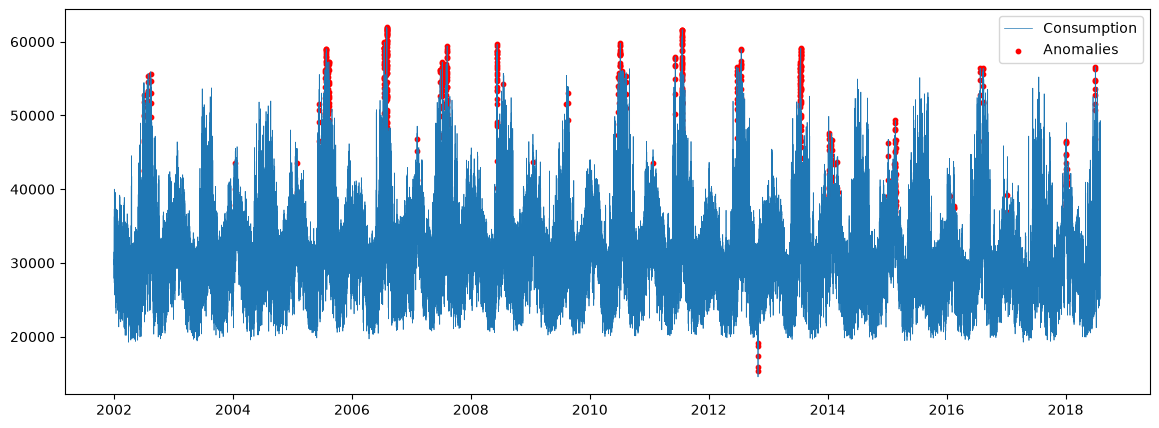

In [12]:
import matplotlib.pyplot as plt

data = preprocess.flag_anomalies(data, "Consumption")
anomalies = data[data["is_anomaly"]]

plt.figure(figsize=(14, 5))
plt.plot(data.index, data["Consumption"], label="Consumption", linewidth=0.5)
plt.scatter(anomalies.index, anomalies["Consumption"], color="red", s=10, label="Anomalies")
plt.legend()
plt.show()